# 01 - Data Cleaning & Exploratory Data Analysis

**Goal:** understand the raw order data, fix quality problems, and explore sales and customer behaviour.

> The data in this repo is *synthetic sample data* so the project runs anywhere. Swap `data/raw/orders.csv`
> for a real dataset (Online Retail II, Olist...) and rerun - the code stays the same.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.append("../src")          # lets us reuse helper functions from src/pipeline.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load the raw data

In [2]:
df = pd.read_csv("../data/raw/orders.csv", parse_dates=["order_date"])
df["customer_id"] = df["customer_id"].astype("Int64")   # nullable integer: IDs stay whole numbers, NaN allowed
print("Shape:", df.shape)
df.head()

Shape: (28325, 11)


,order_id,customer_id,order_date,category,quantity,unit_price,discount_pct,returned,review_score,country,payment_type
0,124117,1845,2025-07-25,Books,1,16.50,0,0,4,India,Credit Card
1,100771,57,2025-04-10,Books,2,6.29,0,0,4,USA,PayPal
2,108129,629,2024-04-30,Home & Kitchen,2,45.15,0,0,5,United Kingdom,Debit Card
3,126992,2104,2024-01-05,Home & Kitchen,3,44.28,20,0,4,India,Credit Card
4,106666,501,2025-12-17,Home & Kitchen,1,44.52,0,1,3,India,PayPal


## 2. Data quality check

In [3]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(), "unique": df.nunique()})
print("Exact duplicate rows:", df.duplicated().sum())
print("Rows with quantity <= 0 (cancellations):", (df["quantity"] <= 0).sum())
quality

Exact duplicate rows: 266
Rows with quantity <= 0 (cancellations): 425


,dtype,nulls,unique
order_id,int64,0,28045
customer_id,Int64,283,2194
order_date,datetime64[us],0,730
category,str,0,6
quantity,int64,0,6
unit_price,float64,0,10250
discount_pct,int64,0,5
returned,int64,0,2
review_score,int64,0,5
country,str,0,6


**Findings:** duplicates, missing `customer_id` values and cancelled orders (negative quantity) must be removed
before analysis. Orders without a customer cannot be used for customer-level analytics.

## 3. Cleaning

In [4]:
steps = []
n = len(df); steps.append(("Raw rows", n))

df = df.drop_duplicates();                       steps.append(("After removing duplicates", len(df)))
df = df.dropna(subset=["customer_id"]);          steps.append(("After dropping missing customer_id", len(df)))
df = df[(df["quantity"] > 0) & (df["unit_price"] > 0)]; steps.append(("After removing cancellations", len(df)))

df["customer_id"] = df["customer_id"].astype(int)
df["total_amount"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)
df["net_amount"] = np.where(df["returned"] == 1, 0.0, df["total_amount"])   # returned orders earn nothing

pd.DataFrame(steps, columns=["Step", "Rows"])

,Step,Rows
0,Raw rows,28325
1,After removing duplicates,28059
2,After dropping missing customer_id,27776
3,After removing cancellations,27356


## 4. Sales trend

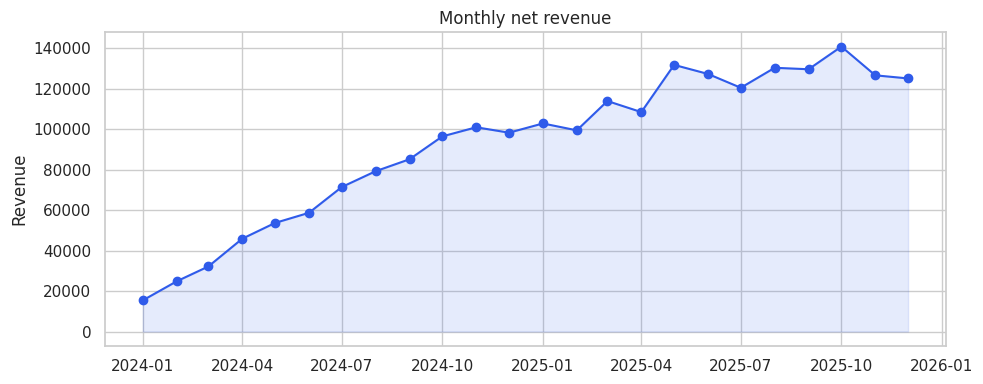

In [5]:
monthly = df.set_index("order_date")["net_amount"].resample("MS").sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker="o", color="#2F5BEA")
ax.fill_between(monthly.index, monthly.values, alpha=0.12, color="#2F5BEA")
ax.set(title="Monthly net revenue", ylabel="Revenue")
plt.tight_layout()

## 5. What sells, and where?

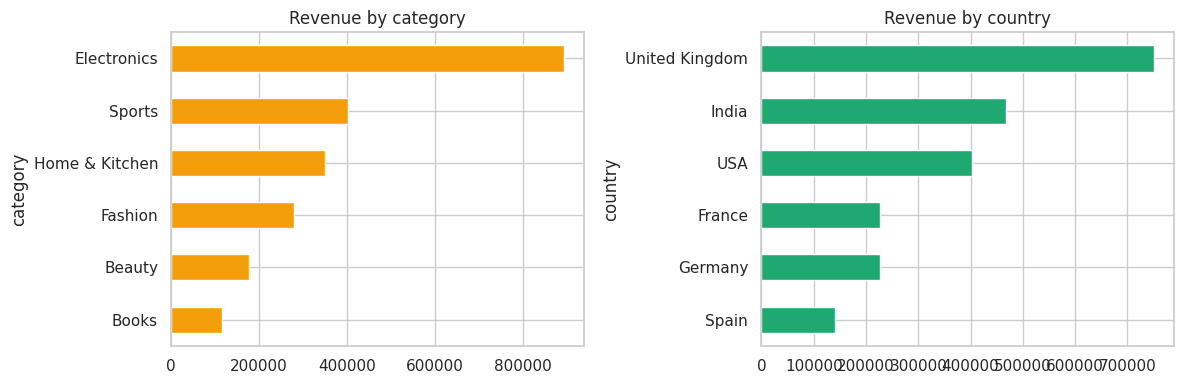

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("category")["net_amount"].sum().sort_values().plot.barh(ax=ax[0], color="#F59E0B")
ax[0].set_title("Revenue by category")
df.groupby("country")["net_amount"].sum().sort_values().plot.barh(ax=ax[1], color="#1FA971")
ax[1].set_title("Revenue by country")
plt.tight_layout()

## 6. Customer behaviour

Customers with only one order: 9.6%
Median orders per customer:    8


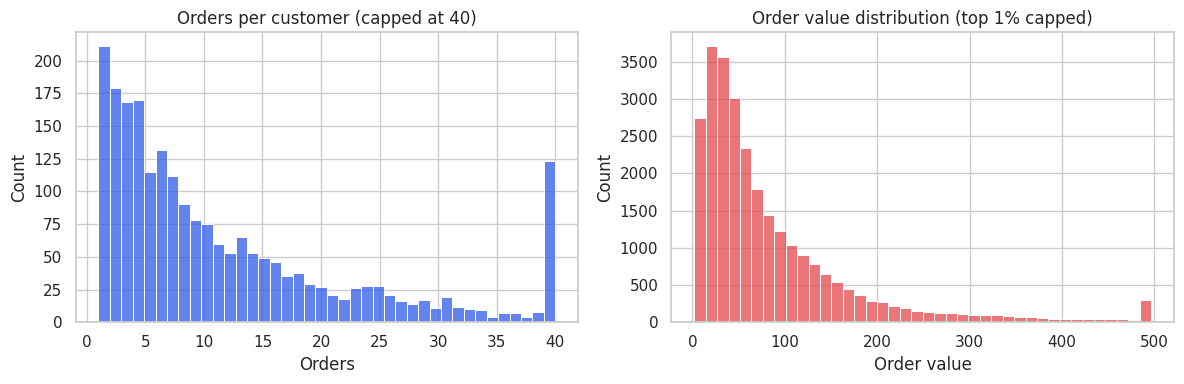

In [7]:
orders_per_customer = df.groupby("customer_id")["order_id"].nunique()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(orders_per_customer.clip(upper=40), bins=40, ax=ax[0], color="#2F5BEA")
ax[0].set(title="Orders per customer (capped at 40)", xlabel="Orders")
sns.histplot(df["total_amount"].clip(upper=df["total_amount"].quantile(0.99)), bins=40, ax=ax[1], color="#E5484D")
ax[1].set(title="Order value distribution (top 1% capped)", xlabel="Order value")
plt.tight_layout()
print(f"Customers with only one order: {(orders_per_customer == 1).mean():.1%}")
print(f"Median orders per customer:    {orders_per_customer.median():.0f}")

## 7. Returns and satisfaction

In [8]:
summary = df.groupby("category").agg(orders=("order_id", "nunique"), return_rate=("returned", "mean"),
                                     avg_review=("review_score", "mean"), avg_discount=("discount_pct", "mean"))
summary.sort_values("return_rate", ascending=False)

,orders,return_rate,avg_review,avg_discount
category,,,,
Home & Kitchen,4502,0.07,3.95,6.82
Books,4769,0.07,3.93,6.64
Sports,4602,0.06,3.92,6.41
Fashion,4560,0.06,3.95,6.77
Beauty,4650,0.06,4.00,6.57
Electronics,4273,0.06,3.98,7.21


### Key takeaways
- About 1 in 10 customers bought only once; the median customer placed 8 orders, so most revenue comes from repeat buyers.
- Electronics brings in about 40% of net revenue even though it has the *fewest* orders - high price per order.
- Return rates and review scores are similar across categories, so they are more useful as **customer-level** churn signals than as category signals.

**Next:** `02_rfm_segmentation_clustering.ipynb`